In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, sys
ROOT = '/content/drive/MyDrive/DSP_Deconv'
for d in ['lib', 'data/raw', 'data/processed', 'results', 'figures', 'configs']:
    os.makedirs(f'{ROOT}/{d}', exist_ok=True)
if f'{ROOT}/lib' not in sys.path:
    sys.path.insert(0, f'{ROOT}/lib')
print(os.listdir(ROOT))

['lib', 'data', 'results', 'figures', 'configs', '03_experiments.ipynb', '02_proposed.ipynb', '04_real_data.ipynb', '00_setup_data.ipynb', '03_experiments_new.ipynb', '04_real_data_new.ipynb', '05_figures_new.ipynb', '02_proposed_new.ipynb', '01_forward_baselines_new.ipynb']


In [ ]:
!pip -q install scikit-image tifffile pyyaml

import sys
import importlib

if "imp" not in sys.modules:
    sys.modules["imp"] = importlib

%load_ext autoreload
%autoreload 2

import numpy as np, scipy, skimage, matplotlib.pyplot as plt
print('numpy', np.__version__, '| scipy', scipy.__version__, '| skimage', skimage.__version__)

numpy 2.1.3 | scipy 1.16.3 | skimage 0.25.2


In [ ]:
import yaml
CFG_PATH = f'{ROOT}/configs/params.yaml'
if not os.path.exists(CFG_PATH):
    cfg = dict(
        seeds=[0, 1, 2, 3, 4],
        psf_sigmas=[1.5, 2.5, 4.0],            
        gauss_noise=[0.005, 0.01, 0.02, 0.05],  
        poisson_peaks=[30, 100, 300],           
        crop=256,                               
        eps_band=1e-3,                          
    )
    yaml.safe_dump(cfg, open(CFG_PATH, 'w'))
cfg = yaml.safe_load(open(CFG_PATH))
cfg

{'crop': 256,
 'eps_band': 0.001,
 'gauss_noise': [0.005, 0.01, 0.02, 0.05],
 'poisson_peaks': [30, 100, 300],
 'psf_sigmas': [1.5, 2.5, 4.0],
 'seeds': [0, 1, 2, 3, 4]}

In [ ]:
import itertools, time, yaml, pandas as pd
from forward import *; from data import *; from baselines import *; from proposed import *; from metrics import *
tuned = yaml.safe_load(open(f'{ROOT}/configs/tuned.yaml'))      # {'nsr': ..., 'rl_iter': ...} from dev set

test_imgs = []
for subset in ['Confocal_BPAE_B', 'TwoPhoton_MICE']:
    gt, _ = fmd_pair(subset, 19)
    for q, crop in enumerate(quadrants(norm_pair(gt)[0])):
        test_imgs.append((f'{subset}_q{q}', crop))

METHODS = {
    'inverse':       lambda y, psf, c: inverse(y, psf),
    'wiener_const':  lambda y, psf, c: wiener_const(y, psf, tuned['nsr']),
    'tikhonov_gcv':  lambda y, psf, c: tikhonov_gcv(y, psf),
    'rl':            lambda y, psf, c: rl(y, psf, tuned['rl_iter']),
    'unsup_wiener':  lambda y, psf, c: unsup_wiener(y, psf),
    'proposed':      lambda y, psf, c: adaptive_wiener(y, psf),
    'oracle_wiener': lambda y, psf, c: wiener_oracle(y, psf, c['x'], c['sigma']),
}

In [ ]:
rows = []
for (name, x), s_psf, s_n, seed in itertools.product(test_imgs, cfg['psf_sigmas'], cfg['gauss_noise'], cfg['seeds']):
    rng = np.random.default_rng(seed)
    psf = gaussian_psf(psf_size(s_psf), s_psf)
    y = add_gaussian(blur(x, psf), s_n, rng)
    for m, f in METHODS.items():
        t0 = time.perf_counter(); xh = f(y, psf, dict(x=x, sigma=s_n)); dt = time.perf_counter() - t0
        xc = np.clip(xh, 0, 1)
        rows.append(dict(img=name, psf=s_psf, noise=s_n, seed=seed, method=m,
                         psnr=psnr(x, xc), ssim=ssim(x, xc), lsd=lsd(x, xc), ms=1e3 * dt))
df = pd.DataFrame(rows)
df.to_csv(f'{ROOT}/results/synthetic_gauss_test.csv', index=False)
df.groupby(['psf', 'noise', 'method'])[['psnr', 'ssim']].agg(['mean', 'std']).round(2)

psnr        ssim      
                          mean   std  mean   std
psf noise method                                
1.5 0.005 inverse         3.37  0.09  0.00  0.00
          oracle_wiener  34.79  1.54  0.90  0.03
          proposed       34.47  1.53  0.88  0.04
          rl             29.62  2.22  0.89  0.04
          tikhonov_gcv   34.53  1.51  0.90  0.04
...                        ...   ...   ...   ...
4.0 0.050 proposed       27.31  1.86  0.68  0.07
          rl             24.61  2.02  0.67  0.06
          tikhonov_gcv   27.29  1.83  0.71  0.04
          unsup_wiener   20.50  0.34  0.18  0.02
          wiener_const   27.13  1.75  0.68  0.03

[84 rows x 4 columns]

In [ ]:
READ = 0.01
pg_rows = []
for (name, x), s_psf, peak, seed in itertools.product(test_imgs, cfg['psf_sigmas'], cfg['poisson_peaks'], cfg['seeds']):
    rng = np.random.default_rng(seed)
    psf = gaussian_psf(psf_size(s_psf), s_psf)
    yb = blur(x, psf)
    y = add_poisson_gaussian(yb, peak, READ, rng)
    sigma_eff = np.sqrt(np.clip(yb, 0, None).mean() / peak + READ ** 2)   
    for m, f in METHODS.items():
        if m == 'inverse': continue
        t0 = time.perf_counter(); xh = f(y, psf, dict(x=x, sigma=sigma_eff)); dt = time.perf_counter() - t0
        xc = np.clip(xh, 0, 1)
        pg_rows.append(dict(img=name, psf=s_psf, peak=peak, seed=seed, sigma_eff=sigma_eff, method=m,
                            psnr=psnr(x, xc), ssim=ssim(x, xc), lsd=lsd(x, xc), ms=1e3 * dt))
pg = pd.DataFrame(pg_rows)
pg.to_csv(f'{ROOT}/results/synthetic_pg_test.csv', index=False)
pg.groupby(['psf', 'peak', 'method'])[['psnr', 'ssim']].agg(['mean', 'std']).round(2)

psnr        ssim      
                         mean   std  mean   std
psf peak method                                
1.5 30   oracle_wiener  30.76  1.69  0.83  0.05
         proposed       30.28  1.69  0.82  0.07
         rl             29.27  2.10  0.86  0.03
         tikhonov_gcv   30.37  1.66  0.84  0.06
         unsup_wiener   27.88  1.06  0.63  0.04
         wiener_const   26.01  1.27  0.59  0.07
    100  oracle_wiener  31.93  1.65  0.86  0.05
         proposed       31.49  1.66  0.85  0.06
         rl             29.50  2.16  0.87  0.04
         tikhonov_gcv   31.58  1.61  0.87  0.05
         unsup_wiener   29.74  1.11  0.71  0.04
         wiener_const   29.42  1.24  0.74  0.05
    300  oracle_wiener  32.76  1.63  0.87  0.04
         proposed       32.36  1.63  0.86  0.06
         rl             29.57  2.19  0.88  0.04
         tikhonov_gcv   32.45  1.59  0.88  0.04
         unsup_wiener   31.01  1.17  0.75  0.04
         wiener_const   31.43  1.30  0.81  0.04
2.5 30   oracle_wiener  29.06  1.81  0.80  0.06
         proposed       28.73  1.81  0.80  0.07
         rl             26.89  2.21  0.83  0.04
         tikhonov_gcv   28.75  1.80  0.82  0.06
         unsup_wiener   23.78  0.73  0.39  0.02
         wiener_const   27.61  1.41  0.72  0.07
    100  oracle_wiener  29.92  1.81  0.82  0.06
         proposed       29.63  1.82  0.82  0.07
         rl             26.95  2.23  0.83  0.04
         tikhonov_gcv   29.65  1.80  0.84  0.06
         unsup_wiener   25.34  0.83  0.45  0.02
         wiener_const   29.32  1.70  0.81  0.05
    300  oracle_wiener  30.54  1.78  0.83  0.05
         proposed       30.27  1.78  0.82  0.07
         rl             26.97  2.24  0.84  0.05
         tikhonov_gcv   30.29  1.77  0.84  0.05
         unsup_wiener   26.47  0.82  0.48  0.02
         wiener_const   30.00  1.82  0.85  0.04
4.0 30   oracle_wiener  27.49  1.96  0.77  0.06
         proposed       27.23  1.97  0.76  0.08
         rl             24.85  2.22  0.78  0.05
         tikhonov_gcv   27.27  1.93  0.78  0.06
         unsup_wiener   20.04  0.58  0.22  0.01
         wiener_const   27.08  1.88  0.77  0.05
    100  oracle_wiener  28.03  1.96  0.79  0.06
         proposed       27.82  1.97  0.78  0.07
         rl             24.87  2.22  0.79  0.05
         tikhonov_gcv   27.84  1.92  0.80  0.06
         unsup_wiener   21.18  0.63  0.24  0.01
         wiener_const   27.60  2.01  0.82  0.05
    300  oracle_wiener  28.45  1.93  0.80  0.06
         proposed       28.25  1.93  0.78  0.07
         rl             24.88  2.22  0.80  0.05
         tikhonov_gcv   28.25  1.92  0.81  0.06
         unsup_wiener   21.98  0.58  0.25  0.02
         wiener_const   27.77  2.05  0.84  0.05

In [ ]:
edge_rows = []
for s_n, seed in itertools.product(cfg['gauss_noise'], cfg['seeds']):
    x = edge_phantom(); psf = gaussian_psf(psf_size(2.5), 2.5)
    y = add_gaussian(blur(x, psf), s_n, np.random.default_rng(seed))
    for m, f in METHODS.items():
        if m == 'inverse': continue
        e = edge_metrics(f(y, psf, dict(x=x, sigma=s_n)))
        edge_rows.append(dict(noise=s_n, seed=seed, method=m, noise_amp=e['flat_std'] / s_n, **e))
pd.DataFrame(edge_rows).to_csv(f'{ROOT}/results/edge_test.csv', index=False)

In [ ]:
from scipy.stats import wilcoxon
tests = []
for label, d, keys in [('gaussian', df, ['img', 'psf', 'noise', 'seed']), ('poisson_gaussian', pg, ['img', 'psf', 'peak', 'seed'])]:
    a = d[d.method == 'proposed'].sort_values(keys).psnr.values
    for base in ['wiener_const', 'tikhonov_gcv', 'rl', 'unsup_wiener']:
        b = d[d.method == base].sort_values(keys).psnr.values
        tests.append(dict(noise_model=label, baseline=base, n=len(a), median_gain_db=np.median(a - b),
                          mean_gain_db=np.mean(a - b), frac_proposed_wins=np.mean(a > b), p_value=wilcoxon(a, b).pvalue))
tests = pd.DataFrame(tests)
tests.to_csv(f'{ROOT}/results/wilcoxon.csv', index=False)
tests.round(4)

,noise_model,baseline,n,median_gain_db,mean_gain_db,frac_proposed_wins,p_value
0,gaussian,wiener_const,480,0.7159,0.9792,1.0000,0.0000
1,gaussian,tikhonov_gcv,480,0.0041,-0.0128,0.5438,0.0469
2,gaussian,rl,480,3.4989,3.4911,1.0000,0.0000
3,gaussian,unsup_wiener,480,3.1364,3.4332,1.0000,0.0000
4,poisson_gaussian,wiener_const,360,0.4708,1.0905,0.9833,0.0000
5,poisson_gaussian,tikhonov_gcv,360,-0.0152,-0.0457,0.3194,0.0000
6,poisson_gaussian,rl,360,2.6374,2.4790,1.0000,0.0000
7,poisson_gaussian,unsup_wiener,360,4.2009,4.2907,1.0000,0.0000


<Axes: xlabel='error_pct', ylabel='mean PSNR (dB)'>

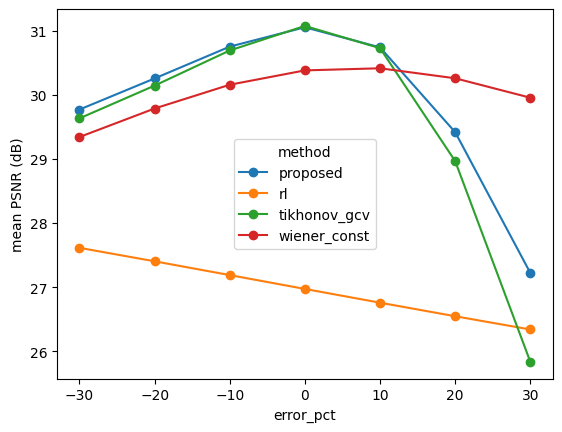

In [ ]:
mis = []
s_true, s_n = 2.5, 0.01
for (name, x), seed in itertools.product(test_imgs, cfg['seeds'][:3]):
    y = add_gaussian(blur(x, gaussian_psf(psf_size(s_true), s_true)), s_n, np.random.default_rng(seed))
    for dlt in [-0.3, -0.2, -0.1, 0, 0.1, 0.2, 0.3]:
        s_used = s_true * (1 + dlt); psf_used = gaussian_psf(psf_size(s_used), s_used)
        for m in ['wiener_const', 'tikhonov_gcv', 'rl', 'proposed']:
            xh = np.clip(METHODS[m](y, psf_used, {}), 0, 1)
            mis.append(dict(img=name, seed=seed, error_pct=100 * dlt, method=m, psnr=psnr(x, xh)))
mis = pd.DataFrame(mis)
mis.to_csv(f'{ROOT}/results/psf_mismatch.csv', index=False)
mis.pivot_table(index='error_pct', columns='method', values='psnr').plot(marker='o', ylabel='mean PSNR (dB)')

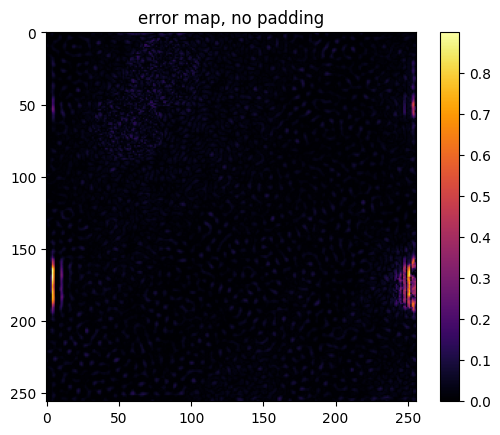

psnr_plain       psnr_padded      
                   mean   std        mean   std
method                                         
proposed          25.95  2.86       28.58  3.43
tikhonov_gcv      14.41  8.75       17.48  9.00
wiener_const      30.24  1.98       30.91  2.39

In [ ]:
psf = gaussian_psf(psf_size(2.5), 2.5)
bnd = []
for name, x in test_imgs:
    y = add_gaussian(blur(x, psf, boundary='reflect'), 0.01, np.random.default_rng(0))
    for m in ['wiener_const', 'tikhonov_gcv', 'proposed']:
        f = lambda im, p: METHODS[m](im, p, {})
        bnd.append(dict(img=name, method=m,
                        psnr_plain=psnr(x, np.clip(f(y, psf), 0, 1)),
                        psnr_padded=psnr(x, np.clip(padded(f, y, psf), 0, 1))))
bnd = pd.DataFrame(bnd)
bnd.to_csv(f'{ROOT}/results/boundary.csv', index=False)

x = test_imgs[0][1]
y = add_gaussian(blur(x, psf, boundary='reflect'), 0.01, np.random.default_rng(0))
plt.imshow(np.abs(np.clip(adaptive_wiener(y, psf), 0, 1) - x), cmap='inferno'); plt.title('error map, no padding'); plt.colorbar()
plt.savefig(f'{ROOT}/figures/boundary_error_map.png', dpi=200); plt.show()
bnd.groupby('method')[['psnr_plain', 'psnr_padded']].agg(['mean', 'std']).round(2)